In [10]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import LabelEncoder

from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

In [11]:
# Load your CSV file
df = pd.read_csv("news.csv")

print(df.head())
print(df.shape)
print(df["label"].value_counts())

   Unnamed: 0                                              title  \
0        8476                       You Can Smell Hillary’s Fear   
1       10294  Watch The Exact Moment Paul Ryan Committed Pol...   
2        3608        Kerry to go to Paris in gesture of sympathy   
3       10142  Bernie supporters on Twitter erupt in anger ag...   
4         875   The Battle of New York: Why This Primary Matters   

                                                text label  
0  Daniel Greenfield, a Shillman Journalism Fello...  FAKE  
1  Google Pinterest Digg Linkedin Reddit Stumbleu...  FAKE  
2  U.S. Secretary of State John F. Kerry said Mon...  REAL  
3  — Kaydee King (@KaydeeKing) November 9, 2016 T...  FAKE  
4  It's primary day in New York and front-runners...  REAL  
(6335, 4)
label
REAL    3171
FAKE    3164
Name: count, dtype: int64


In [12]:
# Clean and prepare the dataset
df = df.dropna(subset=["title", "text", "label"]).copy()

df["news"] = (
    df["title"].astype(str) + " " + df["text"].astype(str)
)

X = df["news"]
y = df["label"].str.strip().str.upper()

print("Total records:", len(df))
print("Classes:", y.unique())
print(y.value_counts())

Total records: 6335
Classes: <ArrowStringArray>
['FAKE', 'REAL']
Length: 2, dtype: str
label
REAL    3171
FAKE    3164
Name: count, dtype: int64


In [13]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 5068
Testing samples: 1267


In [14]:
# Apply CountVectorizer
vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=10000
)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("Training feature shape:", X_train_vec.shape)
print("Testing feature shape:", X_test_vec.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

Training feature shape: (5068, 10000)
Testing feature shape: (1267, 10000)
Vocabulary size: 10000


In [15]:
# Train and compare all models
models = {
    "Linear Regression": "linear",
    "Multinomial NB": MultinomialNB(),
    "Bernoulli NB": BernoulliNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": LinearSVC(random_state=42)
}

encoder = LabelEncoder()
y_train_encoded = encoder.fit_transform(y_train)
y_test_encoded = encoder.transform(y_test)

results = []
trained_models = {}

for name, model in models.items():

    if name == "Linear Regression":
        model = LinearRegression()
        model.fit(X_train_vec, y_train_encoded)

        scores = model.predict(X_test_vec)
        predictions = (scores >= 0.5).astype(int)
        predictions = encoder.inverse_transform(predictions)

    else:
        model.fit(X_train_vec, y_train)
        predictions = model.predict(X_test_vec)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label="FAKE", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label="FAKE", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, pos_label="FAKE", zero_division=0
        )
    })

    trained_models[name] = model

comparison_df = pd.DataFrame(results).sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

print(comparison_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression    0.9258     0.9140  0.9400    0.9268
      Random Forest    0.9069     0.9081  0.9052    0.9066
                SVM    0.9013     0.8944  0.9100    0.9021
     Multinomial NB    0.8698     0.8679  0.8720    0.8700
                KNN    0.8240     0.8060  0.8531    0.8289
       Bernoulli NB    0.8106     0.7631  0.9005    0.8261
      Decision Tree    0.7893     0.7877  0.7915    0.7896
  Linear Regression    0.6922     0.6758  0.7378    0.7054


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


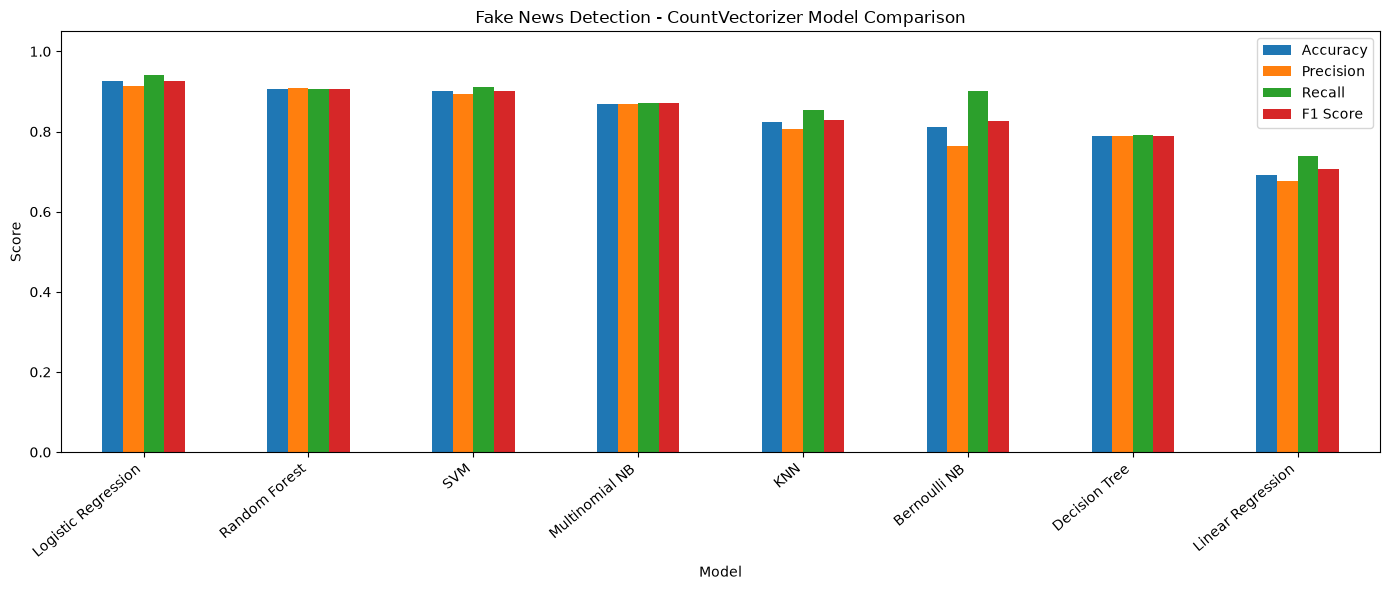

In [17]:
# Visualize the comparison
comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(14, 6))

plt.title("Fake News Detection - CountVectorizer Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

In [18]:
# Identify the best classification model
classification_results = comparison_df[
    comparison_df["Model"] != "Linear Regression"
]

best_model = classification_results.iloc[0]

print("Best model:", best_model["Model"])
print(f"Accuracy: {best_model['Accuracy']:.2%}")
print(f"Precision: {best_model['Precision']:.2%}")
print(f"Recall: {best_model['Recall']:.2%}")
print(f"F1 Score: {best_model['F1 Score']:.2%}")

Best model: Logistic Regression
Accuracy: 92.58%
Precision: 91.40%
Recall: 94.00%
F1 Score: 92.68%


In [19]:
# Predict news from new text
news_text = [
    "Government announces a new public health policy after a press conference."
]

news_vector = vectorizer.transform(news_text)

prediction = trained_models["Logistic Regression"].predict(news_vector)

print("Predicted label:", prediction[0])

Predicted label: FAKE
